# Heart Disease Prediction: end-to-end walkthrough

This notebook walks through the complete ML lifecycle on the
[Kaggle heart disease dataset](https://www.kaggle.com/datasets/johnsmith88/heart-disease-dataset),
one stage at a time. The reusable logic lives in the `src/heart/` package; the notebook imports it
and shows each step, its results and the reasoning behind every decision.

> ⚠️ **Educational project, not a diagnostic tool.** The model predicts a *dataset label*. It does not
> diagnose real patients and its output is not medical advice.

**Stages:** 1 Problem · 2 Data · 3 EDA · 4 Cleaning · 5 Preprocessing · 6 Features · 7 Models ·
8 Evaluation · 9 CV & tuning · 10 Interpretation · 11 Selection · 12 Deployment

In [1]:
import sys, warnings
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(PROJECT_ROOT / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.exceptions import UndefinedMetricWarning

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UndefinedMetricWarning)
pd.set_option("display.precision", 3)
sns.set_theme(style="whitegrid", context="notebook")

from heart import config
print("Project root:", PROJECT_ROOT)
print("Random state:", config.RANDOM_STATE)

Project root: /home/claude/heart-disease-prediction
Random state: 42


## 1. Problem understanding

* **Task:** supervised **binary classification**. Each patient record has a known label
  (disease / no disease), and the model learns to map the 13 clinical features to that label.
* **Output:** a probability, turned into a decision by a **threshold** we choose deliberately.
* **Errors are not equal.** A *false negative* (a disease case predicted healthy) can mean a person
  at risk gets no follow-up. A *false positive* means extra tests and worry. For screening we
  prioritise **sensitivity** (recall on disease) while keeping specificity reasonable.
* **Label ≠ diagnosis.** A probability of 0.8 means *records like this were usually labelled disease
  in this dataset*, not *this person has an 80% chance of heart disease*.

## 2. Data understanding

First rule: **inspect before assuming.** We load the raw file and validate its schema.

In [2]:
from heart.data import load_raw

raw = load_raw()          # also checks the columns are exactly what we expect
print(raw.shape)
raw.head()

(1025, 14)


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,52,1,0,125,212,0,1,168,0,1.0,2,2,3,0
1,53,1,0,140,203,1,0,155,1,3.1,0,0,3,0
2,70,1,0,145,174,0,1,125,1,2.6,0,0,3,0
3,61,1,0,148,203,0,1,161,0,0.0,2,1,3,0
4,62,0,0,138,294,1,1,106,0,1.9,1,3,2,0


In [3]:
raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 1025 entries, 0 to 1024
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1025 non-null   int64  
 1   sex       1025 non-null   int64  
 2   cp        1025 non-null   int64  
 3   trestbps  1025 non-null   int64  
 4   chol      1025 non-null   int64  
 5   fbs       1025 non-null   int64  
 6   restecg   1025 non-null   int64  
 7   thalach   1025 non-null   int64  
 8   exang     1025 non-null   int64  
 9   oldpeak   1025 non-null   float64
 10  slope     1025 non-null   int64  
 11  ca        1025 non-null   int64  
 12  thal      1025 non-null   int64  
 13  target    1025 non-null   int64  
dtypes: float64(1), int64(13)
memory usage: 112.2 KB


In [4]:
pd.DataFrame({
    "meaning": pd.Series(config.FEATURE_DESCRIPTIONS),
    "n_unique": raw[config.FEATURES].nunique(),
    "min": raw[config.FEATURES].min(),
    "max": raw[config.FEATURES].max(),
})

,meaning,n_unique,min,max
age,Age in years,41,29.0,77.0
ca,Number of major vessels coloured by fluoroscop...,5,0.0,4.0
chol,Serum cholesterol (mg/dl),152,126.0,564.0
cp,"Chest pain type (4 categories, coded 0-3)",4,0.0,3.0
exang,Exercise-induced angina (1 = yes),2,0.0,1.0
fbs,Fasting blood sugar > 120 mg/dl (1 = true),2,0.0,1.0
oldpeak,ST depression induced by exercise relative to ...,40,0.0,6.2
restecg,Resting ECG result (coded 0-2),3,0.0,2.0
sex,"Sex (1 = male, 0 = female)",2,0.0,1.0
slope,Slope of the peak exercise ST segment (coded 0-2),3,0.0,2.0


Every column is stored as a number, but they are not all *quantities*:

| Group | Columns | Treatment |
|---|---|---|
| Continuous | `age`, `trestbps`, `chol`, `thalach`, `oldpeak` | impute median, standardise |
| Binary | `sex`, `fbs`, `exang` | already 0/1 |
| Nominal (codes are labels) | `cp`, `restecg`, `slope`, `thal` | **one-hot encode** |
| Ordinal count | `ca` (vessels 0–3) | keep numeric: the order is meaningful |

Treating `cp = 3` as "three times" `cp = 1` would impose a false order and spacing on what are just category labels.

## 3–4. Data quality checks and cleaning

Before any plots, we check the data itself. These checks changed the whole project.

In [5]:
print("Missing values:", int(raw.isna().sum().sum()))
print("Duplicate rows:", int(raw.duplicated().sum()), "of", len(raw))
print("Unique rows:   ", len(raw.drop_duplicates()))

Missing values: 0
Duplicate rows: 723 of 1025
Unique rows:    302


### Finding 1: 70% of the rows are duplicates

Only **302** rows are unique. If we split the 1,025 rows randomly, copies of the same patient land in
both train and test, so the model gets tested on rows it has memorised. That is **data leakage**, and
it explains the 98–100% accuracies often reported on this dataset. We keep one copy of each row.

In [6]:
for col, allowed in config.VALID_CODES.items():
    bad = raw.drop_duplicates().loc[~raw.drop_duplicates()[col].isin(allowed), col]
    if len(bad):
        print(f"{col}: invalid values {sorted(bad.unique())} in {len(bad)} unique rows (allowed {sorted(allowed)})")

ca: invalid values [np.int64(4)] in 4 unique rows (allowed [0, 1, 2, 3])
thal: invalid values [np.int64(0)] in 2 unique rows (allowed [1, 2, 3])


### Finding 2: invalid category codes

`ca` counts vessels 0–3, so `4` is impossible; `thal` has three categories, so `0` is not one of them.
These most likely mean *not recorded*. We set them to `NaN` and let the pipeline **impute** them,
instead of inventing a category or deleting the patient.

In [7]:
uniq = raw.drop_duplicates()
markers = ["thalach", "oldpeak", "exang", "ca", "age", "sex"]
uniq.groupby("target")[markers].mean().T.rename(columns={0: "raw target = 0", 1: "raw target = 1"})

target,raw target = 0,raw target = 1
thalach,139.101,158.378
oldpeak,1.586,0.587
exang,0.551,0.140
ca,1.167,0.341
age,56.601,52.585
sex,0.826,0.561


### Finding 3: the `target` column is inverted

Clinically, heart disease goes with a **lower** maximum heart rate, **more** ST depression, **more**
exercise-induced angina and **more** blocked vessels. In this file, those all belong to `target = 0`.
So `target = 1` behaves like *no disease*, the opposite of the dataset's description.

This matters a lot: we want to maximise recall on **disease**. If we trusted the column as documented,
we would be carefully minimising missed *healthy* patients instead.

**Decision:** model `has_disease = 1 − target` (`config.INVERT_TARGET`). Cross-check: after the flip
there are 138 disease cases, the same as the original UCI Cleveland data.

In [8]:
from heart.data import clean_data, make_label

clean, report = clean_data(raw)
y_all = make_label(clean)
print(report)
print("\nModelling label counts:")
print(y_all.value_counts().rename({1: "disease (1)", 0: "no disease (0)"}))

CleaningReport(rows_in=1025, duplicates_removed=723, rows_out=302, invalid_codes_set_missing={'ca': 4, 'thal': 2})

Modelling label counts:
has_disease
no disease (0)    164
disease (1)       138
Name: count, dtype: int64


## 3. Exploratory data analysis

From here on, all analysis uses the cleaned, de-duplicated data and the corrected label.

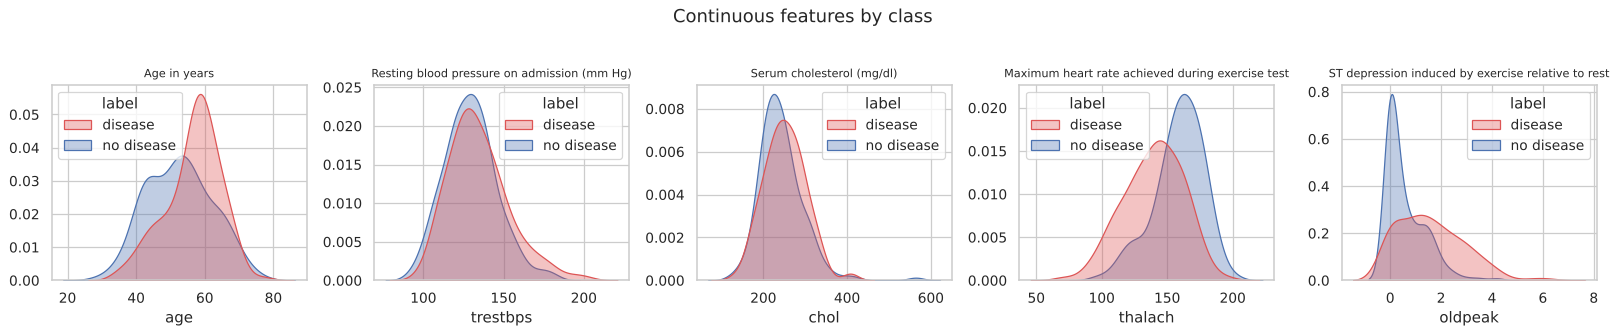

In [9]:
eda = clean.copy()
eda["label"] = y_all.map({0: "no disease", 1: "disease"})
palette = {"no disease": "#4C72B0", "disease": "#DD5555"}

fig, axes = plt.subplots(1, 5, figsize=(18, 3.6))
for ax, col in zip(axes, config.NUMERIC_FEATURES):
    sns.kdeplot(data=eda, x=col, hue="label", fill=True, common_norm=False,
                palette=palette, alpha=0.35, ax=ax)
    ax.set_title(config.FEATURE_DESCRIPTIONS[col], fontsize=9); ax.set_ylabel("")
fig.suptitle("Continuous features by class", y=1.03); plt.tight_layout(); plt.show()

`thalach` (max heart rate) is clearly lower and `oldpeak` (ST depression) clearly higher in the disease
group. `chol` and `trestbps` overlap heavily, so on their own they separate the classes poorly.

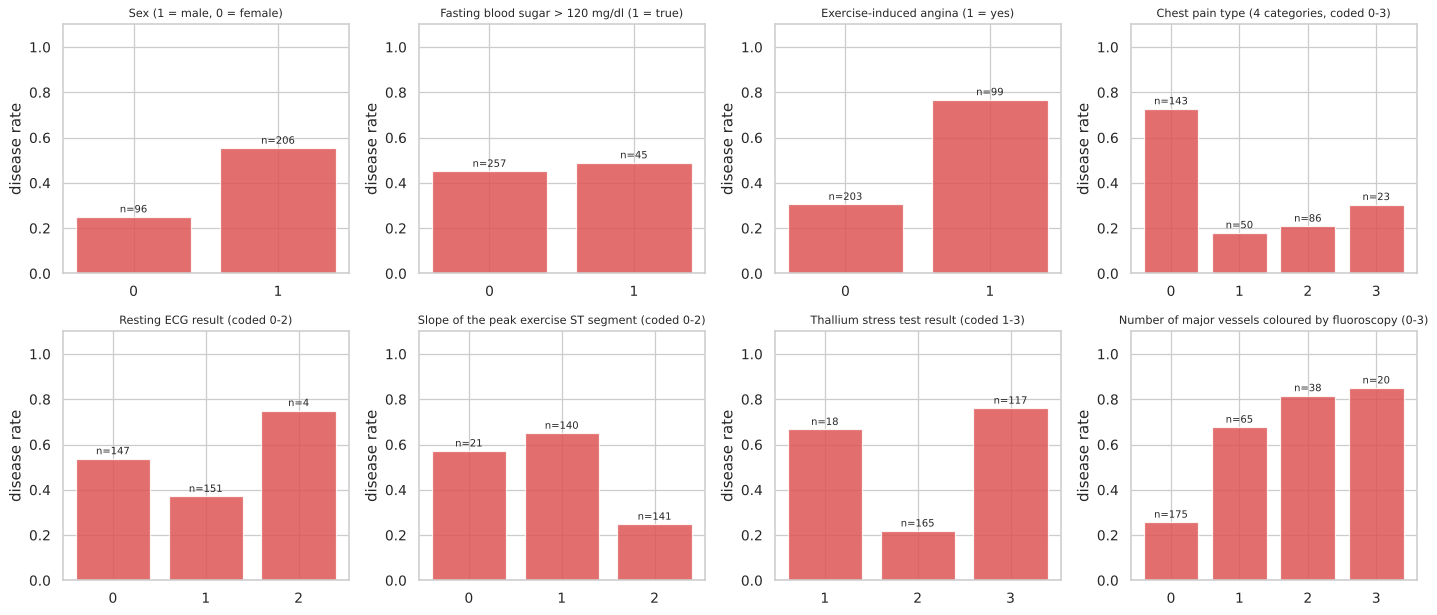

In [10]:
cats = config.BINARY_FEATURES + config.NOMINAL_FEATURES + config.ORDINAL_FEATURES
fig, axes = plt.subplots(2, 4, figsize=(16, 7))
for ax, col in zip(axes.ravel(), cats):
    rate = eda.assign(y=y_all).groupby(col)["y"].agg(["mean", "size"])
    ax.bar(rate.index.astype(int).astype(str), rate["mean"], color="#DD5555", alpha=0.85)
    for i, (m, n) in enumerate(zip(rate["mean"], rate["size"])):
        ax.text(i, m + 0.02, f"n={n}", ha="center", fontsize=8)
    ax.set_ylim(0, 1.1); ax.set_title(config.FEATURE_DESCRIPTIONS[col], fontsize=9)
    ax.set_ylabel("disease rate")
plt.tight_layout(); plt.show()

* `cp = 0` has a ~73% disease rate versus ~18–30% for the other chest-pain codes. This is consistent
  with *asymptomatic* chest pain in the original UCI coding (silent ischaemia found on testing).
* Disease rate climbs steadily with `ca` (0 → 3 vessels): a genuine ordinal relationship.
* `thal = 3` (≈ reversible defect) is mostly disease; `thal = 2` (≈ normal) mostly not.
* **Representation:** about 2/3 of patients are male, so the model has much less evidence about women.

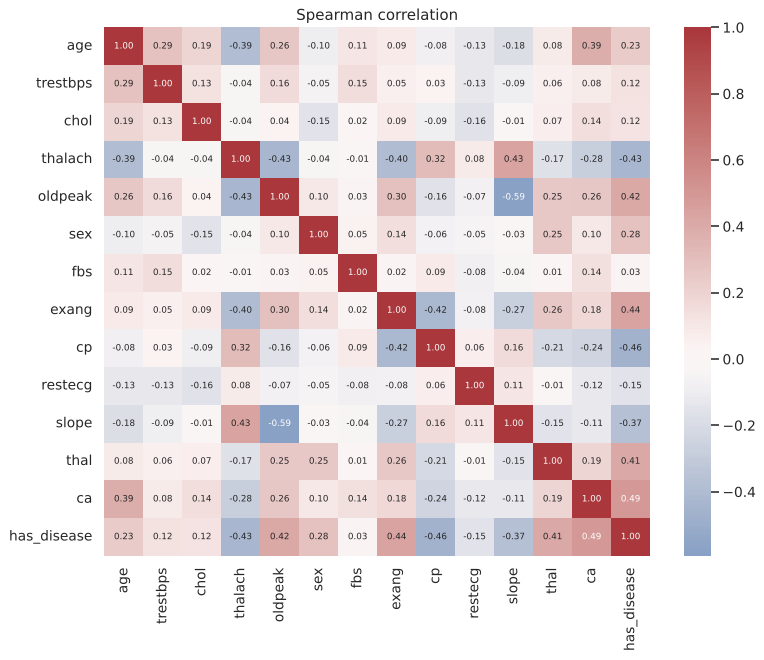

,rho
ca,0.493
cp,-0.460
exang,0.436
thalach,-0.426
oldpeak,0.420
thal,0.410
slope,-0.369
sex,0.284
age,0.235
restecg,-0.146


In [11]:
corr = eda[config.FEATURES].assign(has_disease=y_all).corr(method="spearman")
plt.figure(figsize=(9, 7.5))
sns.heatmap(corr, cmap="vlag", center=0, annot=True, fmt=".2f", annot_kws={"size": 7})
plt.title("Spearman correlation"); plt.tight_layout(); plt.show()
corr["has_disease"].drop("has_disease").sort_values(key=abs, ascending=False).to_frame("rho")

We use **Spearman** (rank) correlation because it is robust to skew and to coded categories, and it
captures monotonic relationships, not only linear ones. Weak correlation alone is **not** a reason
to drop a feature: it may still help in combination with others.

In [12]:
from heart.eda import iqr_outliers
iqr_outliers(clean)

,feature,lower_fence,upper_fence,n_outliers,outlier_values
0,age,28.500,80.500,0,[]
1,trestbps,90.000,170.000,9,"[172, 174, 178, 178, 180, 180, 180, 192, 200]"
2,chol,115.375,370.375,5,"[394, 407, 409, 417, 564]"
3,thalach,84.125,215.125,1,[71]
4,oldpeak,-2.400,4.000,5,"[4.2, 4.2, 4.4, 5.6, 6.2]"


The 1.5×IQR rule flags a handful of extreme values (cholesterol 564, ST depression 6.2, blood
pressure 200). All are physiologically possible, so we **keep them**. Deleting real extreme
patients would hide exactly the cases a clinical model must handle. Median imputation, standardised
logistic regression and tree models all cope well with them.

## 5. Train/test split and preprocessing

**The test set is split off now and not touched again until the very end.** Every decision
(features, model, hyperparameters, threshold) is made with cross-validation on the training set.

In [13]:
from heart.data import split_data

X, y = clean[config.FEATURES], y_all
X_train, X_test, y_train, y_test = split_data(X, y)   # stratified 80/20, random_state=42
print(f"train {X_train.shape}, disease rate {y_train.mean():.3f}")
print(f"test  {X_test.shape}, disease rate {y_test.mean():.3f}")
overlap = X_train.merge(X_test, how="inner", on=list(X.columns))
print("Identical rows shared by train and test:", len(overlap))

train (241, 13), disease rate 0.456
test  (61, 13), disease rate 0.459
Identical rows shared by train and test: 0


### Why a `Pipeline` prevents leakage

Imputers and scalers *learn* numbers from data (medians, means, standard deviations). Fitting them on
the full dataset would let test-set statistics leak into training. Wrapping them with the model in a
single `Pipeline` means `cross_validate` and `GridSearchCV` **re-fit preprocessing inside each training
fold**, and the deployed app applies exactly the same transformations.

In [14]:
from heart.features import build_preprocessor

pre = build_preprocessor()
Xt = pre.fit_transform(X_train)          # fitted on TRAIN only
print("Transformed shape:", Xt.shape)
print(list(pre.get_feature_names_out()))
pre

Transformed shape: (241, 22)
['num__age', 'num__trestbps', 'num__chol', 'num__thalach', 'num__oldpeak', 'bin__sex', 'bin__fbs', 'bin__exang', 'nom__cp_0.0', 'nom__cp_1.0', 'nom__cp_2.0', 'nom__cp_3.0', 'nom__restecg_0.0', 'nom__restecg_1.0', 'nom__restecg_2.0', 'nom__slope_0.0', 'nom__slope_1.0', 'nom__slope_2.0', 'nom__thal_1.0', 'nom__thal_2.0', 'nom__thal_3.0', 'ord__ca']


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('columns', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](13,)","['age','trestbps','chol',...,'slope','thal','ca']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,13
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('bin', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the

## 6. Feature engineering

Clinical idea: max heart rate falls with age, so raw `thalach` isn't comparable across ages. The
engineered feature `pct_max_hr = thalach / (220 − age)` measures *what share of their age-predicted
maximum the patient reached*. We test with cross-validation whether it actually helps.

In [15]:
from heart.train import compare_feature_sets

fe = compare_feature_sets(X_train, y_train)
fe.pivot(index="model", columns="engineered_feature", values="cv_roc_auc").rename(
    columns={False: "without", True: "with pct_max_hr"})

engineered_feature,without,with pct_max_hr
model,,
Decision Tree,0.753,0.740
Gradient Boosting,0.889,0.889
K-Nearest Neighbors,0.877,0.866
Logistic Regression,0.909,0.909
Random Forest,0.910,0.904
SVM (RBF),0.906,0.902


It doesn't help (it is slightly worse for most models). The models can already combine `age` and
`thalach`, so the ratio adds nothing new and only costs a little variance. **Decision:** don't use it.
A sensible idea that fails validation is still a useful, honest result to report.

## 7. Model development: baseline vs six algorithms (untuned)

| Model | Idea | Why it is a candidate |
|---|---|---|
| Baseline | always predicts the class prior | the bar every model must beat |
| Logistic regression | weighted sum → sigmoid | strong on small tabular data, interpretable |
| KNN | vote of the *k* most similar patients | simple, non-parametric; needs scaling |
| Decision tree | learned if/else rules | readable; overfits easily |
| Random forest | average of many randomised trees | lowers a single tree's variance |
| SVM (RBF) | maximum-margin, curved boundary | strong on small scaled data |
| Gradient boosting | trees added sequentially to fix errors | often best on tabular data |

We evaluate each with **5-fold stratified CV repeated 5 times** (25 fits). With only ~240 training
rows a single split is noisy; repetition gives a stable mean and a standard deviation.

In [16]:
from sklearn.base import clone
from heart.features import build_pipeline
from heart.models import get_baseline, get_model_specs
from heart.train import cv_summary

rows = [{"model": get_baseline().name, "version": "baseline",
         **cv_summary(build_pipeline(get_baseline().estimator), X_train, y_train)}]
for spec in get_model_specs():
    rows.append({"model": spec.name, "version": "untuned",
                 **cv_summary(build_pipeline(clone(spec.estimator)), X_train, y_train)})
untuned = pd.DataFrame(rows)
untuned[["model", "cv_roc_auc", "cv_roc_auc_std", "cv_recall", "cv_precision", "cv_accuracy"]]

,model,cv_roc_auc,cv_roc_auc_std,cv_recall,cv_precision,cv_accuracy
0,Baseline (majority class),0.500,0.000,0.000,0.000,0.544
1,Logistic Regression,0.909,0.044,0.796,0.846,0.839
2,K-Nearest Neighbors,0.877,0.046,0.767,0.820,0.816
3,Decision Tree,0.753,0.049,0.725,0.739,0.755
4,Random Forest,0.910,0.041,0.785,0.862,0.841
5,SVM (RBF),0.906,0.041,0.756,0.867,0.833
6,Gradient Boosting,0.889,0.043,0.765,0.803,0.804


Every model beats the baseline by a wide margin. The untuned **decision tree** is clearly worst: a
fully grown tree memorises the training folds. That makes it a good case for tuning.

## 9. Hyperparameter tuning (GridSearchCV, train only)

Grids are deliberately small. On small data, large grids mostly find settings that fit the noise
in particular folds. Scoring is **ROC-AUC**, which measures ranking quality independent of the
threshold (we choose the threshold separately in stage 8).

In [17]:
from sklearn.model_selection import GridSearchCV, StratifiedKFold

tune_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=config.RANDOM_STATE)
tuned_pipes, tuned_rows = {}, []
for spec in get_model_specs():
    search = GridSearchCV(build_pipeline(clone(spec.estimator)), spec.param_grid,
                          scoring="roc_auc", cv=tune_cv, n_jobs=-1).fit(X_train, y_train)
    tuned_pipes[spec.name] = search.best_estimator_
    tuned_rows.append({"model": spec.name, "version": "tuned",
                       "best_params": {k.replace("model__", ""): v for k, v in search.best_params_.items()},
                       **cv_summary(clone(search.best_estimator_), X_train, y_train)})
tuned = pd.DataFrame(tuned_rows)

comparison = (untuned[untuned.version == "untuned"].set_index("model")[["cv_roc_auc"]]
              .join(tuned.set_index("model")[["cv_roc_auc", "cv_roc_auc_std", "best_params"]],
                    lsuffix="_untuned", rsuffix="_tuned"))
comparison

,cv_roc_auc_untuned,cv_roc_auc_tuned,cv_roc_auc_std,best_params
model,,,,
Logistic Regression,0.909,0.911,0.040,"{'C': 0.3, 'l1_ratio': 1.0, 'solver': 'saga'}"
K-Nearest Neighbors,0.877,0.910,0.039,"{'n_neighbors': 21, 'p': 1, 'weights': 'distan..."
Decision Tree,0.753,0.858,0.049,"{'criterion': 'gini', 'max_depth': 3, 'min_sam..."
Random Forest,0.910,0.918,0.037,"{'max_depth': 5, 'max_features': 'sqrt', 'min_..."
SVM (RBF),0.906,0.913,0.041,"{'C': 1, 'gamma': 0.01}"
Gradient Boosting,0.889,0.910,0.041,"{'learning_rate': 0.1, 'max_depth': 1, 'n_esti..."


* Tuning helped most where the defaults overfit: the **decision tree** (limited to depth 3) and
  **KNN** (21 neighbours instead of 5).
* **Logistic regression** barely changed: it was already well regularised.
* After tuning, five models sit within about 0.01 AUC of each other. With ±0.04 fold-to-fold
  standard deviation, these differences are mostly noise.

*Caveat:* scoring a tuned configuration with CV on the same data is slightly optimistic. Nested CV
would remove that bias, and the untouched test set gives the final, unbiased check.

## 11. Model selection (before looking at the test set)

**Rule:** take the best tuned CV ROC-AUC, then among models within **one standard error** of it,
prefer the simplest. Small differences in a noisy estimate shouldn't buy complexity.

In [18]:
best = tuned.loc[tuned.cv_roc_auc.idxmax()]
se = best.cv_roc_auc_std / np.sqrt(config.CV_SPLITS * config.CV_REPEATS)
simplicity = ["Logistic Regression", "K-Nearest Neighbors", "SVM (RBF)", "Decision Tree",
              "Random Forest", "Gradient Boosting"]
contenders = tuned[tuned.cv_roc_auc >= best.cv_roc_auc - se]
selected = min(contenders.model, key=simplicity.index)
print(f"Best CV ROC-AUC: {best.model} = {best.cv_roc_auc:.3f}   (1 SE = {se:.3f})")
print("Within 1 SE:", list(contenders.model))
print("Selected:", selected)
final_pipe = tuned_pipes[selected]

Best CV ROC-AUC: Random Forest = 0.918   (1 SE = 0.007)
Within 1 SE: ['Logistic Regression', 'Random Forest', 'SVM (RBF)']
Selected: Logistic Regression


Logistic regression is within 0.007 of the random forest, so it is selected. It is interpretable,
gives well-behaved probabilities and is the simplest model that performs as well as the others.

## 8. Choosing the decision threshold (still train only)

The default threshold of 0.5 is arbitrary. To prioritise catching disease, we pick the **highest
threshold that reaches 90% sensitivity**, which keeps as much specificity as possible at that target.

We pick it on **out-of-fold** predictions: each training patient is scored by a model that did not
see them, so the scores behave like unseen data, without using the test set.

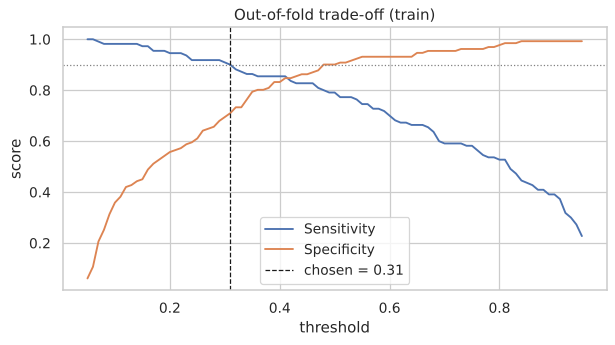

,threshold,accuracy,precision,recall_sensitivity,specificity,f1,roc_auc,tn,fp,fn,tp
threshold 0.50,0.50,0.851,0.870,0.791,0.901,0.829,0.912,118,13,23,87
threshold 0.31,0.31,0.797,0.723,0.900,0.710,0.802,0.912,93,38,11,99


In [19]:
from sklearn.model_selection import cross_val_predict
from heart.evaluate import choose_threshold, compute_metrics, specificity_score, recall_score

oof = cross_val_predict(clone(final_pipe), X_train, y_train, cv=tune_cv, method="predict_proba")[:, 1]
threshold = choose_threshold(y_train, oof, config.TARGET_SENSITIVITY)

ts = np.linspace(0.05, 0.95, 91)
sens = [recall_score(y_train, (oof >= t).astype(int)) for t in ts]
spec = [specificity_score(y_train, (oof >= t).astype(int)) for t in ts]
plt.figure(figsize=(7, 4))
plt.plot(ts, sens, label="Sensitivity"); plt.plot(ts, spec, label="Specificity")
plt.axvline(threshold, ls="--", c="k", lw=1, label=f"chosen = {threshold:.2f}")
plt.axhline(config.TARGET_SENSITIVITY, ls=":", c="grey", lw=1)
plt.xlabel("threshold"); plt.ylabel("score"); plt.legend(); plt.title("Out-of-fold trade-off (train)")
plt.tight_layout(); plt.show()

pd.DataFrame([compute_metrics(y_train, oof, 0.5), compute_metrics(y_train, oof, threshold)],
             index=["threshold 0.50", f"threshold {threshold:.2f}"])

Moving from 0.5 to the chosen threshold catches more disease cases (fewer false negatives) at the
cost of more false alarms (lower specificity). **Where to sit on this curve is a clinical and
ethical choice**; the 90% target is an illustrative screening assumption.

## 8. Final evaluation on the test set (used once)

All choices are now fixed. We score the held-out 61 patients exactly once.

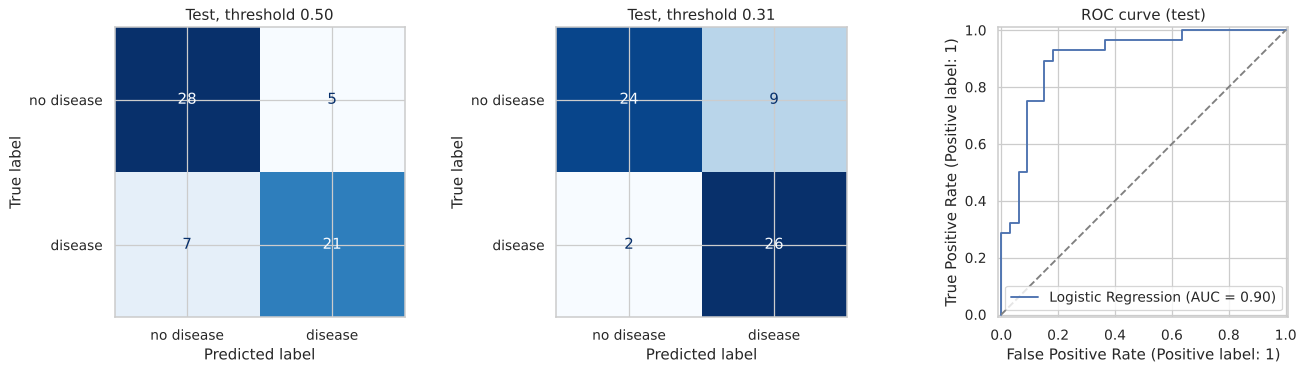

,threshold,accuracy,precision,recall_sensitivity,specificity,f1,roc_auc,tn,fp,fn,tp
threshold 0.50,0.50,0.803,0.808,0.750,0.848,0.778,0.902,28,5,7,21
threshold 0.31,0.31,0.820,0.743,0.929,0.727,0.825,0.902,24,9,2,26


In [20]:
from sklearn.metrics import ConfusionMatrixDisplay, RocCurveDisplay

test_proba = final_pipe.predict_proba(X_test)[:, 1]
results = pd.DataFrame([compute_metrics(y_test, test_proba, 0.5),
                        compute_metrics(y_test, test_proba, threshold)],
                       index=["threshold 0.50", f"threshold {threshold:.2f}"])

fig, axes = plt.subplots(1, 3, figsize=(15, 4.3))
for ax, t in zip(axes[:2], [0.5, threshold]):
    ConfusionMatrixDisplay.from_predictions(y_test, (test_proba >= t).astype(int),
        display_labels=["no disease", "disease"], cmap="Blues", colorbar=False, ax=ax)
    ax.set_title(f"Test, threshold {t:.2f}")
RocCurveDisplay.from_predictions(y_test, test_proba, ax=axes[2], name=selected)
axes[2].plot([0, 1], [0, 1], "--", c="grey"); axes[2].set_title("ROC curve (test)")
plt.tight_layout(); plt.show()
results

**Reading the results**

* At the chosen threshold the model catches **26 of 28** disease cases (sensitivity ≈ 0.93), versus
  21 of 28 at 0.5. **Five fewer missed cases cost four more false alarms.**
* Specificity falls from ≈ 0.85 to ≈ 0.73: about a quarter of healthy patients get flagged for follow-up.
* ROC-AUC ≈ 0.90 is close to the cross-validation estimate (≈ 0.91), which suggests the CV process was honest.
* With 61 test patients, each metric has roughly ±0.1 uncertainty. One patient is about 3.6
  percentage points of sensitivity.

In [21]:
# Transparency only: every tuned model on the test set. NOT used to choose anything.
pd.DataFrame([{"model": n, **compute_metrics(y_test, p.predict_proba(X_test)[:, 1], 0.5)}
              for n, p in tuned_pipes.items()]).set_index("model")[
    ["roc_auc", "accuracy", "recall_sensitivity", "specificity", "f1"]]

,roc_auc,accuracy,recall_sensitivity,specificity,f1
model,,,,,
Logistic Regression,0.902,0.803,0.750,0.848,0.778
K-Nearest Neighbors,0.897,0.820,0.786,0.848,0.800
Decision Tree,0.851,0.770,0.750,0.788,0.750
Random Forest,0.891,0.803,0.750,0.848,0.778
SVM (RBF),0.906,0.852,0.786,0.909,0.830
Gradient Boosting,0.870,0.770,0.821,0.727,0.767


SVM happens to look best on the test set. If we switched to it *now*, we'd be using the test set
for model selection, and its score would stop being an unbiased estimate. Differences of this size on
61 patients are within noise anyway.

## 10. Model interpretation

Three complementary views:
1. **Permutation importance** (model-agnostic): how much test ROC-AUC drops when a feature is shuffled.
2. **Odds ratios** (logistic regression): direction and size of each feature's effect.
3. **A single prediction** broken into per-feature contributions.

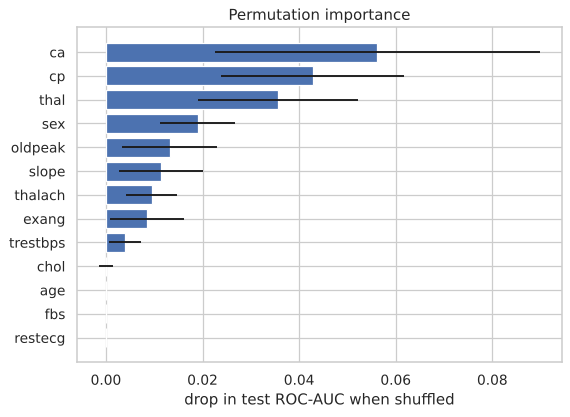

In [22]:
from heart.interpret import permutation_table, linear_coefficients, explain_one

perm = permutation_table(final_pipe, X_test, y_test)
plt.figure(figsize=(6.5, 4.8))
p = perm.iloc[::-1]
plt.barh(p.feature, p.importance_mean, xerr=p.importance_std, color="#4C72B0")
plt.xlabel("drop in test ROC-AUC when shuffled"); plt.title("Permutation importance")
plt.tight_layout(); plt.show()

In [23]:
coefs = linear_coefficients(final_pipe)
coefs[coefs.coefficient != 0]

,feature,coefficient,odds_ratio
0,nom__cp_0.0,1.228,3.415
1,ord__ca,1.024,2.785
2,nom__thal_3.0,0.916,2.499
3,bin__exang,0.604,1.830
4,bin__sex,0.500,1.649
5,num__oldpeak,0.469,1.598
6,nom__slope_1.0,0.383,1.467
7,nom__thal_2.0,-0.228,0.796
8,num__thalach,-0.203,0.817
9,nom__slope_2.0,-0.114,0.893


**How to read an odds ratio.** Numeric features are standardised, so their effect is per one
standard deviation. For example, `bin__exang` ≈ 1.8: exercise-induced angina multiplies the *odds* of
the disease label by about 1.8, holding the other features fixed.

The strongest signals are `cp = 0`, more vessels (`ca`), `thal = 3`, exercise angina, male sex and ST
depression, which matches the EDA. **L1 regularisation set `age`, `fbs` and `restecg` to zero**: their
information is already carried by correlated features, so the model performs feature selection inside
cross-validation instead of us dropping columns by hand.

Remember: this is **association, not causation**, and it describes what the model uses to reproduce
*this dataset's* labels.

In [24]:
i = int(np.argmax(test_proba))
print(f"Highest-scored test patient: probability {test_proba[i]:.2f}, "
      f"dataset label = {'disease' if y_test.iloc[i] else 'no disease'}")
display_df = explain_one(final_pipe, X_test.iloc[[i]])
display_df

Highest-scored test patient: probability 0.99, dataset label = disease


,feature,contribution
21,ord__ca,2.613
8,nom__cp_0.0,1.228
4,num__oldpeak,1.168
20,nom__thal_3.0,0.916
16,nom__slope_1.0,0.383
1,num__trestbps,0.102


For a linear model, the log-odds is a sum of `coefficient × scaled value` terms, so every prediction
can be explained exactly. Here, three coloured vessels, `cp = 0` and high ST depression push the score
strongly towards the disease label.

## 12. Deployment

`python -m heart.train` runs exactly this workflow and saves **the whole pipeline** (preprocessing +
model) together with the threshold and metadata. Saving them together means the app can't
accidentally apply different preprocessing from training. Below, we load the saved artefact and check
it matches the notebook.

In [25]:
from heart.predict import load_model, predict_one

saved_pipe, meta = load_model()
print("Saved model:", meta["model_name"], "| threshold:", meta["threshold"])
print("Matches notebook threshold:", np.isclose(meta["threshold"], threshold))
print("Same test probabilities:  ", np.allclose(saved_pipe.predict_proba(X_test)[:, 1], test_proba))

example = {"age": 58, "sex": 1, "cp": 0, "trestbps": 140, "chol": 260, "fbs": 0, "restecg": 1,
           "thalach": 130, "exang": 1, "oldpeak": 2.0, "slope": 1, "ca": 2, "thal": 3}
predict_one(example)

Saved model: Logistic Regression | threshold: 0.31
Matches notebook threshold: True
Same test probabilities:   True


Prediction(probability=0.9848546907078325, threshold=0.31, flagged=True, model_name='Logistic Regression')

The Streamlit interface wraps `predict_one`:

```bash
streamlit run app/streamlit_app.py
```

## Limitations and next steps

* **Small sample:** 302 unique patients; every metric carries wide uncertainty.
* **Representativeness:** 1980s referral population, single study, about 68% male. Performance for women,
  other populations and present-day patients is unknown. Probabilities are not calibrated for a general
  screening population, where disease is far rarer than 46%.
* **Feature availability:** the most influential features (`ca`, `thal`) come from fluoroscopy and
  thallium stress tests, which are rarely available at a screening stage.
* **Label and code ambiguity** in this Kaggle copy (stages 3–4).

**Extensions:** nested cross-validation · bootstrap confidence intervals · calibration curves ·
subgroup metrics by sex · external validation on the other UCI sites (Hungary, Switzerland, VA).